# Deliverable 2 — Image Denoising with Convolutional Autoencoders

**Business context.** TouNum digitizes paper archives in bulk. The scans come in very different
qualities: some are blurry or **noisy** (grain, scanner sensor noise, compression). Noise hurts the next
steps of the pipeline: the captioning network (deliverable 3) would describe the noise instead of the
content. So before captioning, we clean the photos.

**The idea.** We take clean photos, add noise to them on purpose, and teach a neural network to give back
the clean photo from the noisy one. It is *supervised* learning: we know the right answer for each noisy
image, because we made the noise ourselves.

**The tool: a convolutional autoencoder.** It squeezes the image into a smaller representation
(*encoder*), then rebuilds a full-size image from it (*decoder*). Noise is random and hard to squeeze,
while the real content (shapes, colours, edges) is regular: the network learns to keep the content and
drop the noise.

We compare three autoencoders, from the simplest to the most efficient:
1. **Simple convolutional autoencoder** (baseline) — *section 5.1*
2. **U-Net autoencoder** (skip connections) — *section 5.2*
3. Residual autoencoder (DnCNN style) — *to come*

In [1]:
import tensorflow as tf, keras
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1791715462.416315    5859 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.21.0 | Keras 3.15.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Imports and Configuration

The libraries, where the files are, the image size, the noise level and the random seed.

In [2]:
print("[Block 1] Imports and configuration : starting...")

import hashlib, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio.v3 as iio          # asked by the assignment: used to read information about the images
import tensorflow as tf
import keras
from keras import layers

# Fixed seed: same shuffling, same noise, same starting weights on every run.
# So when two models get different scores, it comes from the models, not from luck.
SEED = 42
keras.utils.set_random_seed(SEED)   # sets the Python, NumPy and TensorFlow seeds at once

# Where the files are. Paths are relative to the notebook folder (/workspace in the Docker container).
ROOT = Path("")
DATA = ROOT / "data"         # photos of deliverable 1, already split: data/{train,val,test}/photo. We only read them
RESULTS = ROOT / "results"   # trained models (.keras) and the results table (.csv)
LOGS = RESULTS / "logs"      # training logs (CSV + TensorBoard)
RESULTS.mkdir(exist_ok=True)
LOGS.mkdir(exist_ok=True)

IMG_SIZE = (256, 256)   # every photo is resized to 256 x 256 pixels, in colour (RGB)
BATCH = 4              # smaller than deliverable 1: an autoencoder keeps big images in every layer, it needs more memory
# Noise (section 3): 3 types, each with a strength drawn at random in a range (pixels between 0 and 1)
NOISE_TYPES = ["gaussian", "salt_pepper", "poisson"]
GAUSS_STD = (0.05, 0.20)       # Gaussian: standard deviation of the grain (0.05 = light, 0.20 = heavy)
SP_AMOUNT = (0.01, 0.10)       # salt and pepper: share of pixels turned white or black (1 % to 10 %)
POISSON_PEAK = (10.0, 60.0)    # Poisson: number of "photons" for a white pixel (fewer photons = more noise)
MIN_SIDE = IMG_SIZE[0]  # photos with a side under 256 px would be enlarged (blurred): not used as clean targets

print("[Block 1] OK")

[Block 1] Imports and configuration : starting...
[Block 1] OK


## 2. The Data: checking and cleaning the photos

We reuse the **photos** of deliverable 1, already split into train (70 %) / validation (15 %) /
test (15 %): `data/train/photo`, `data/val/photo`, `data/test/photo`. We keep this split as it is: the test
photos are the same as in deliverable 1, and none of them is ever used for training.

Before training, we open **every photo once** (same method as deliverable 1) and write down what we see in
a table, one row per photo:

| Column | In plain words |
|---|---|
| `path`, `split` | Where the photo is, and which part (train / val / test) it belongs to |
| `readable` | Can TensorFlow open it? |
| `width`, `height` | Its size in pixels |
| `mode` | Colour (RGB), grey (L), with transparency (RGBA)… |
| `md5` | Its "fingerprint": two identical files get the same code, even with different names |

Then we remove three kinds of photos:
1. **Unreadable** files: one broken file could crash the training after an hour.
2. **Exact copies** (same MD5). A copy in train *and* in test would mean the model has already seen a test
   photo (*data leakage*): the copy is always removed from val / test, the train one is kept.
3. **Photos smaller than 256 px** on one side. This rule is **specific to denoising**. In deliverable 1 we
   only removed icons (< 32 px), because a slightly blurry photo is still a photo. Here, the clean photo is
   the **answer the model must give back**. A small photo enlarged to 256 × 256 becomes blurry, so we would
   teach the model that a blurry result is correct.

The table is saved in `data/denoise_index.csv` (cache): next runs read it instantly instead of opening
~10,000 photos again. If the photos change, run `build_index(force=True)`.

In [3]:
print("[Block 2a] Photo index : starting...")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}   # other files (e.g. desktop.ini) are skipped
SPLITS = ["train", "val", "test"]

def inspect_image(path):
    # Open one file and write down what the checks need: fingerprint, colour mode, size, can we open it?
    raw = path.read_bytes()
    info = {"md5": hashlib.md5(raw).hexdigest(), "mode": None,
            "width": None, "height": None, "readable": False}
    try:
        info["mode"] = iio.immeta(path).get("mode")   # L = grey, RGB = colour, RGBA = colour + transparency
        img = tf.io.decode_image(raw, channels=3, expand_animations=False)   # same opening tool as the training
        info["height"], info["width"] = int(img.shape[0]), int(img.shape[1])
        info["readable"] = True
    except Exception:
        pass   # empty, cut off, or a format TensorFlow cannot open: it stays readable = False
    return info

def build_index(force=False):
    # One row per photo of data/{train,val,test}/photo
    cache = DATA / "denoise_index.csv"
    if cache.exists() and not force:   # table already saved: read it instead of opening all the photos again
        print(f"  index read from {cache}")
        return pd.read_csv(cache)
    rows = []
    for split in SPLITS:   # train first: when two files are copies, the train one is kept (block 2b)
        files = sorted(f for f in (DATA / split / "photo").iterdir() if f.suffix.lower() in IMAGE_EXTENSIONS)
        print(f"  {split}/photo : {len(files)} files, inspecting...")
        with ThreadPoolExecutor() as pool:   # opens several files at the same time, to go faster
            infos = list(pool.map(inspect_image, files))
        rows += [{"path": f.as_posix(), "split": split, **i} for f, i in zip(files, infos)]
    index = pd.DataFrame(rows)
    index.to_csv(cache, index=False)   # save the table for next time
    return index

index = build_index()
print(f"  {len(index)} photos indexed")

print("[Block 2a] OK")

[Block 2a] Photo index : starting...
  index read from data/denoise_index.csv
  9993 photos indexed
[Block 2a] OK


In [4]:
print("[Block 2b] Quality check and cleaning : starting...")

index["too_small"] = index[["width", "height"]].min(axis=1) < MIN_SIDE   # would be enlarged, so blurred
index["duplicate"] = index.duplicated("md5", keep="first")                # same fingerprint as an earlier photo

# Summary per split: number of photos, number of problems, typical size, colour modes
quality = index.groupby("split").agg(
    photos=("path", "size"),
    unreadable=("readable", lambda s: (~s).sum()),
    too_small=("too_small", "sum"),
    exact_duplicates=("duplicate", "sum"),
    median_width=("width", "median"),
    median_height=("height", "median"),
).reindex(SPLITS)
modes = pd.crosstab(index["split"], index["mode"].fillna("?"))   # number of photos per colour mode
display(quality.join(modes))
print("  unreadable files:", index.loc[~index.readable, "path"].tolist())

# Cleaning. `index` keeps every row (to see what was removed), `df` is the clean table used from now on
df = index[index.readable & ~index.too_small & ~index.duplicate].copy()

# Safety check: the same photo (same fingerprint) must never be in two parts
assert df.groupby("md5")["split"].nunique().max() == 1, "the same photo is in two splits"

kept = df["split"].value_counts().reindex(SPLITS)
print(f"  {len(index)} -> {len(df)} photos after cleaning ({len(index) - len(df)} removed)")
print("  kept per split:", kept.to_dict())

print("[Block 2b] OK")

[Block 2b] Quality check and cleaning : starting...


,photos,unreadable,too_small,exact_duplicates,median_width,median_height,L,RGB
split,,,,,,,,
train,6995,0,43,0,640.0,480.0,12,6983
val,1499,0,7,0,640.0,480.0,8,1491
test,1499,0,9,0,640.0,480.0,5,1494


  unreadable files: []
  9993 -> 9934 photos after cleaning (59 removed)
  kept per split: {'train': 6952, 'val': 1492, 'test': 1490}
[Block 2b] OK


### 2.1 Loading the Images (tf.data)

The clean table only holds the **paths** of the photos. Each photo is:
1. read from its file and decoded in **RGB** (3 channels: grey or transparent images become colour images);
2. resized to 256 × 256 (with *antialiasing*, so the resizing itself does not add jagged edges that the
   model would take for noise);
3. kept in memory (`cache`) as whole numbers from 0 to 255: about 1.4 GB for the training photos.
   The photos are decoded only once, not at every epoch.

The pixels are turned into numbers **between 0 and 1** just before going into the model (section 3).

In [5]:
print("[Block 2c] Loading the images : starting...")

AUTOTUNE = tf.data.AUTOTUNE   # let TensorFlow choose how many images to prepare at the same time

def load_image(path):
    # Open one photo, force RGB, resize to 256 x 256, store as whole numbers 0-255 (4 times lighter than decimals)
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])                          # "this is a colour image": resize needs to know it
    img = tf.image.resize(img, IMG_SIZE, antialias=True)    # stretched to 256 x 256, not cropped
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)

# Paths of the clean photos of each part, sorted so the order is the same on every computer
paths = {split: sorted(df.loc[df.split == split, "path"]) for split in SPLITS}
for split, p in paths.items():
    print(f"  {split:5s}: {len(p):5d} photos")

print("[Block 2c] OK")

[Block 2c] Loading the images : starting...
  train:  6952 photos
  val  :  1492 photos
  test :  1490 photos
[Block 2c] OK


## 3. Adding Noise: building the (noisy, clean) pairs

The network learns from **pairs**: the input is the noisy photo, the expected answer is the clean photo.
We make the noisy photo ourselves from the clean one.

**Why several types of noise?** On the day of the defense, TouNum gives us images we have never seen, with a
noise we do not know. A model trained on one single noise (one type, one strength) only knows how to remove
*that* noise. So each training photo gets **one of 3 types of noise, chosen at random, with a random
strength**. These 3 types are the classic noises of digitized images:

| Noise | What it looks like | Where it comes from | Formula (pixels in [0, 1]) |
|---|---|---|---|
| **Gaussian** | fine grain everywhere, in all colours | electronic noise of the scanner / camera sensor | $\text{clean} + \mathcal{N}(0, \sigma^2)$, $\sigma \in [0.05, 0.20]$ |
| **Salt and pepper** | isolated white and black dots | dust, dead pixels, transmission errors | a share $p \in [1\%, 10\%]$ of the pixels becomes white or black |
| **Poisson** | grain that is **stronger in the light areas** | the sensor counts light particles (photons): the count varies at random | $\text{Poisson}(\text{clean} \times k) / k$, $k \in [10, 60]$ |

The result is always clipped to [0, 1] (`clip`).

- **Training images: new noise at every epoch** (new type, new strength). The model never sees the same noisy
  version twice, so it cannot learn the noise by heart: it has to learn what noise *is*. It works like data
  augmentation.
- **Validation images: always the same noise.** Each image gets its noise from a fixed seed (the seed + its
  position in the list): the type and the strength are random, but the same on every run.
- **Test images: one test set per type of noise** (the same test photos, three times). So in section 7 we
  can see which noise each model removes well, and which one it struggles with.

[Block 3] Noise and pairs : starting...


W0000 00:00:1791715475.031688    5859 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1791715475.032169    5859 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2243 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


  test photos shown: [680, 933, 837, 1039]


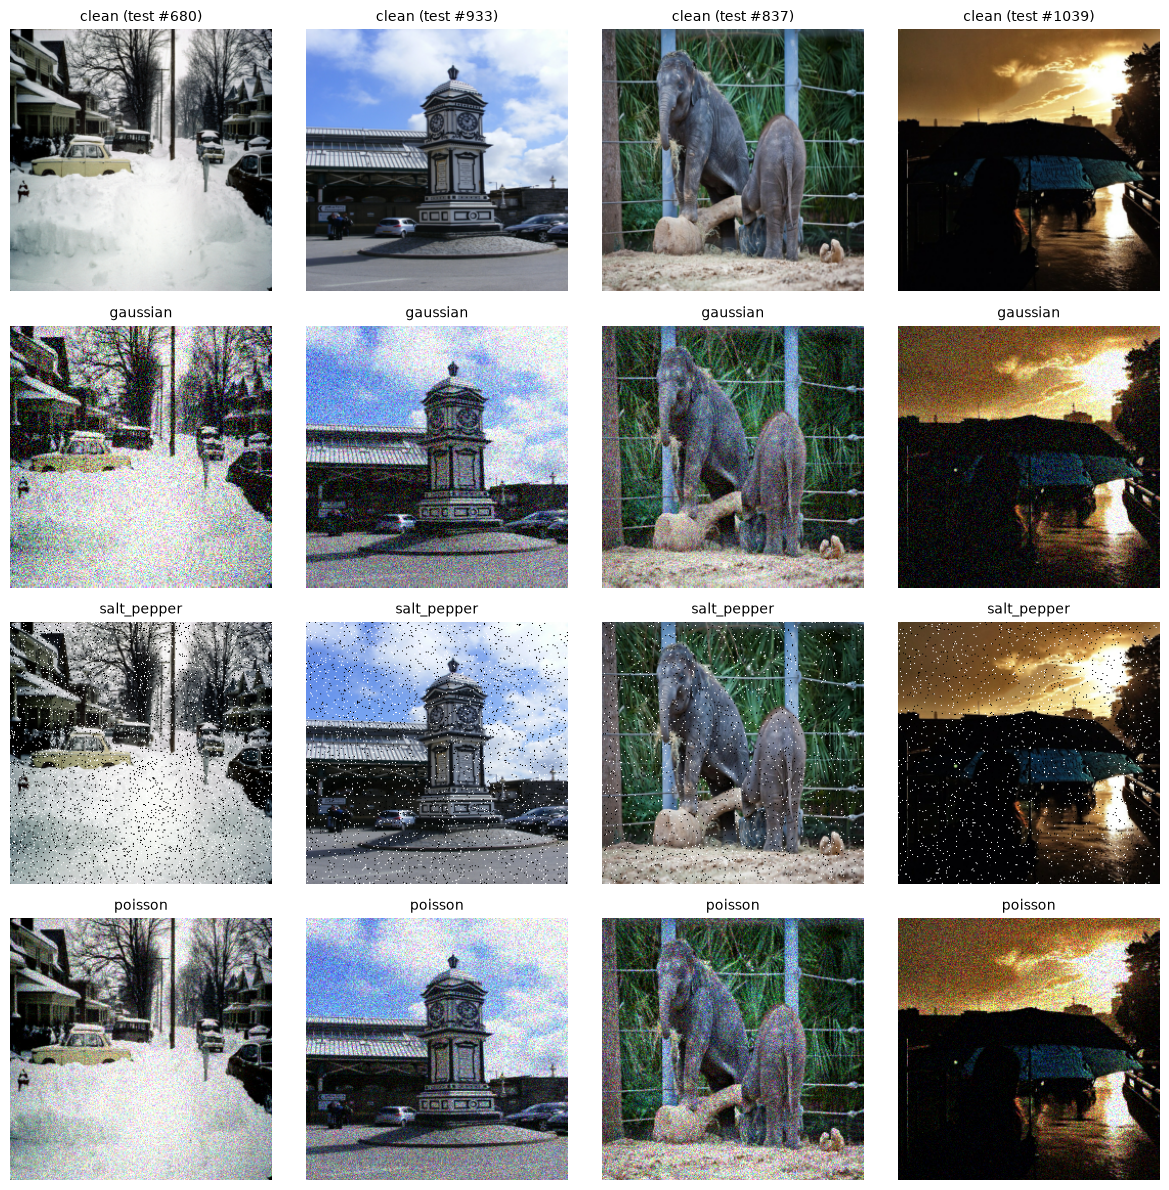

[Block 3] OK


In [6]:
print("[Block 3] Noise and pairs : starting...")

# Every random draw below is "stateless": it is computed from a seed (2 numbers). Same seed -> same noise.
# split_seed turns one seed into 2 new independent seeds (one for the strength, one for the noise itself)
def split_seed(seed):
    return tf.unstack(tf.random.experimental.stateless_split(seed, num=2))

def strength(seed, low_high):
    # A random strength between low and high
    return tf.random.stateless_uniform([], seed, minval=low_high[0], maxval=low_high[1])

def gaussian_noise(clean, seed):
    s_strength, s_noise = split_seed(seed)
    sigma = strength(s_strength, GAUSS_STD)
    return clean + tf.random.stateless_normal(tf.shape(clean), s_noise, stddev=sigma)   # small value added to every pixel

def salt_pepper_noise(clean, seed):
    s_strength, s_noise = split_seed(seed)
    amount = strength(s_strength, SP_AMOUNT)
    u = tf.random.stateless_uniform(tf.shape(clean)[:2], s_noise)[..., None]   # one draw per pixel, same for R, G, B
    out = tf.where(u < amount / 2, 1.0, clean)        # half of the hit pixels become white (salt)
    return tf.where(u > 1 - amount / 2, 0.0, out)     # the other half become black (pepper)

def poisson_noise(clean, seed):
    s_strength, s_noise = split_seed(seed)
    peak = strength(s_strength, POISSON_PEAK)
    # Each pixel = a count of photons, drawn around clean * peak. Bright pixels -> big counts -> more variation
    return tf.random.stateless_poisson(tf.shape(clean), s_noise, lam=clean * peak, dtype=tf.float32) / peak

NOISE_FUNCTIONS = [gaussian_noise, salt_pepper_noise, poisson_noise]   # same order as NOISE_TYPES

def add_noise(clean, seed, kind=None):
    # kind=None -> one of the 3 noises chosen at random (from the seed). kind="poisson" -> always this one
    s_kind, s_noise = split_seed(seed)
    if kind is None:
        k = tf.random.stateless_uniform([], s_kind, minval=0, maxval=len(NOISE_FUNCTIONS), dtype=tf.int32)
        noisy = tf.switch_case(k, [lambda f=f: f(clean, s_noise) for f in NOISE_FUNCTIONS])
    else:
        noisy = NOISE_FUNCTIONS[NOISE_TYPES.index(kind)](clean, s_noise)
    return tf.clip_by_value(noisy, 0.0, 1.0)   # pixels stay between 0 and 1

def make_pair(img, seed, kind=None):
    # uint8 image 0-255 -> (noisy input, clean target), both in [0, 1]
    clean = tf.cast(img, tf.float32) / 255.0
    return add_noise(clean, seed, kind), clean

def make_dataset(split, kind=None):
    ds = tf.data.Dataset.from_tensor_slices(paths[split])
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()   # decoded once, then kept in memory
    if split == "train":
        ds = ds.shuffle(len(paths[split]), seed=SEED)              # new order at every epoch
        # a new random seed for every photo at every epoch -> new type and new strength of noise every time
        ds = ds.map(lambda img: make_pair(img, tf.random.uniform([2], maxval=2**62, dtype=tf.int64)),
                    num_parallel_calls=AUTOTUNE)
    else:
        # fixed noise: the seed of image number i is (SEED, i), the same on every run
        ds = ds.enumerate().map(lambda i, img: make_pair(img, tf.stack([tf.constant(SEED, tf.int64), i]), kind),
                                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_dataset("train")                                         # random noise type, changes every epoch
val_ds = make_dataset("val")                                             # random noise type, fixed
test_sets = {kind: make_dataset("test", kind) for kind in NOISE_TYPES}   # one test set per noise type, fixed

def test_pair(i, kind):
    # Test photo number i with the given noise: exactly the same noise as in test_sets (same seed (SEED, i))
    return make_pair(load_image(paths["test"][i]), tf.constant([SEED, i], tf.int64), kind)

# Look at 4 random test photos with each type of noise: it checks the noise before training.
# No seed here on purpose: other photos at every run (the noise of each photo stays the same)
picks = np.random.default_rng().choice(len(paths["test"]), size=4, replace=False)
print("  test photos shown:", picks.tolist())
fig, axes = plt.subplots(1 + len(NOISE_TYPES), 4, figsize=(12, 3 * (1 + len(NOISE_TYPES))))
for col, i in enumerate(picks):
    for row, kind in enumerate(NOISE_TYPES):
        noisy, clean = test_pair(i, kind)
        axes[row + 1, col].imshow(noisy); axes[row + 1, col].set_title(f"{kind}", fontsize=10)
    axes[0, col].imshow(clean); axes[0, col].set_title(f"clean (test #{i})", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("[Block 3] OK")

## 4. Measuring the Quality: PSNR and SSIM

To compare the models we need numbers, not only pictures. We use the two standard measures of image
restoration, always comparing the output of the model with the **clean** photo:

| Measure | What it looks at | How to read it |
|---|---|---|
| **PSNR** (*Peak Signal-to-Noise Ratio*, in dB) | the average pixel error: $\text{PSNR} = 10 \log_{10}\left(\frac{1}{\text{MSE}}\right)$ for pixels in [0, 1] | higher is better. +3 dB ≈ error divided by 2. Above ~30 dB the noise is hard to see |
| **SSIM** (*Structural Similarity*, 0 to 1) | whether local **structures** match: brightness, contrast, edges and textures, window by window | higher is better, 1 = identical. Closer to what a human eye notices than PSNR |

The two do not always agree: a model that blurs the image can get a decent PSNR (the average error is
small) but a poor SSIM (the textures and edges are gone). That is why we keep both.

**Reference point: doing nothing.** We first score the noisy test images as they are, for each type of
noise. A model is only useful if it does better than this.

In [7]:
print("[Block 4] Quality measures : starting...")

# Registered so that the saved models (.keras) can be loaded again with these metrics
@keras.saving.register_keras_serializable(package="leyenda")
def psnr(clean, denoised):
    return tf.image.psnr(clean, denoised, max_val=1.0)   # one value per image, in dB

@keras.saving.register_keras_serializable(package="leyenda")
def ssim(clean, denoised):
    return tf.image.ssim(clean, denoised, max_val=1.0)   # one value per image, between 0 and 1

def score(ds, model=None):
    # Average PSNR and SSIM over a whole dataset. model=None scores the noisy input itself ("do nothing")
    psnrs, ssims = [], []
    for noisy, clean in ds:
        out = noisy if model is None else model(noisy, training=False)
        psnrs.append(psnr(clean, out).numpy())
        ssims.append(ssim(clean, out).numpy())
    return float(np.mean(np.concatenate(psnrs))), float(np.mean(np.concatenate(ssims)))

def score_all(model=None):
    # PSNR and SSIM on each test set (one per noise type), then the average over the 3 noise types
    row = {}
    for kind, ds in test_sets.items():
        row[f"{kind} PSNR"], row[f"{kind} SSIM"] = score(ds, model)
    row["mean PSNR"] = np.mean([row[f"{k} PSNR"] for k in NOISE_TYPES])
    row["mean SSIM"] = np.mean([row[f"{k} SSIM"] for k in NOISE_TYPES])
    return row

scores = {"Noisy input (no denoising)": score_all()}   # filled with one row per model in section 7
display(pd.DataFrame(scores).T.round(3))

print("[Block 4] OK")

[Block 4] Quality measures : starting...


,gaussian PSNR,gaussian SSIM,salt_pepper PSNR,salt_pepper SSIM,poisson PSNR,poisson SSIM,mean PSNR,mean SSIM
Noisy input (no denoising),19.248,0.336,18.049,0.433,19.303,0.386,18.866,0.385


[Block 4] OK


## 5. The Denoising Autoencoders

### 5.1 Type 1 — Simple Convolutional Autoencoder (baseline)

The simplest denoising autoencoder, our reference point. It has two symmetric halves:

```
input 256x256x3
  ENCODER   Conv 32 -> MaxPool   (128x128x32)
            Conv 64 -> MaxPool   ( 64x 64x64)   <- latent space (bottleneck)
  DECODER   Conv 64 -> UpSample  (128x128x64)
            Conv 32 -> UpSample  (256x256x32)
            Conv 3, sigmoid      (256x256x3)    <- denoised RGB image
```

- **Encoder.** Each `Conv2D` slides small 3 × 3 filters over the image to find local patterns (edges,
  colours, textures). Each `MaxPooling2D` keeps the strongest value of each 2 × 2 square: the image becomes
  2 times smaller in each direction. After two of them, the image is a 64 × 64 grid: this is the
  **latent space**. It is too small to keep every pixel, so the network must keep what matters (the content)
  and drop what is random (the noise).
- **Decoder.** The mirror of the encoder: each `UpSampling2D` doubles the size of the grid (each value is
  copied into a 2 × 2 square), and the `Conv2D` that follows learns to fill in the details.
- **Last layer: `Conv2D(3, sigmoid)`.** 3 filters = the 3 colour channels R, G, B. The *sigmoid* keeps
  every output pixel between 0 and 1, the same range as the clean images.
- **`padding='same'`** everywhere: a convolution does not shrink the image, only the pooling does. So the
  output has exactly the size of the input.

**Expected weakness.** Everything has to go through the small 64 × 64 grid. The fine details lost there
cannot come back: we expect a clean but **blurry** image. This is exactly what the U-Net (type 2) fixes.

**Result (section 7):** the type 1 model gains about +10 dB over the noisy input, but the case study shows the expected blur: fine textures (stripes, faces, small objects) are smoothed out.

In [8]:
print("[Block 5] Type 1 - simple autoencoder : definition...")

def build_cdae(name="CDAE_baseline", input_shape=IMG_SIZE + (3,)):
    inp = keras.Input(shape=input_shape)
    # Encoder: find the patterns, then shrink the image
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)   # 32 filters of 3 x 3: edges, colours
    x = layers.MaxPooling2D(2, padding="same")(x)                      # 256 -> 128
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)     # 64 filters: bigger patterns
    x = layers.MaxPooling2D(2, padding="same")(x)                      # 128 -> 64: latent space (bottleneck)
    # Decoder: grow the image back and fill in the details
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)                                      # 64 -> 128
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)                                      # 128 -> 256
    out = layers.Conv2D(3, 3, activation="sigmoid", padding="same")(x) # 3 channels (RGB), pixels in [0, 1]
    return keras.Model(inp, out, name=name)

build_cdae().summary()

print("[Block 5] OK")

[Block 5] Type 1 - simple autoencoder : definition...


Model: "CDAE_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 256, 256, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

[Block 5] OK


### 5.2 Type 2 — U-Net Autoencoder (skip connections)

**U-Net** is an architecture published in 2015 (Ronneberger et al.) for medical images. It is drawn as a
**U**: the encoder goes down on the left, the bottleneck is at the bottom, the decoder goes up on the right.
It is the standard choice when the input and the output are images of the same size, like in denoising.

**Same encoder and decoder as type 1, plus shortcuts.** Each level of the encoder sends a copy of its
feature maps **directly** to the level of the decoder that has the same size (*skip connection*). The decoder
glues it to what comes up from the bottleneck (`Concatenate`) before its convolution:

```
input 256x256x3
  ENCODER   Conv 32 (256x256) ─────────────────────────────┐ skip 1 (fine details)
            MaxPool -> Conv 64 (128x128) ──────────┐       │ skip 2 (medium details)
            MaxPool -> Conv 64 (64x64)  <- bottleneck       │
  DECODER   UpSample -> Concatenate(skip 2) -> Conv 32 (128x128)
            UpSample -> Concatenate(skip 1) -> Conv 32 (256x256)
            Conv 3, sigmoid (256x256x3)  <- denoised RGB image
```

- **The bottleneck** still sees the whole image in small: it knows *what is noise and what is content*,
  but it has lost the fine details.
- **The skip connections** carry the fine details (edges, textures), but still with their noise.
- **The decoder combines both:** it keeps the sharp details from the shortcuts, and uses the bottleneck
  to know which ones are real.

**Why does it not just copy the noisy input through the shortcut?** It could, but copying the noise gives a
big error (MSE) against the clean photo: training pushes it to use the shortcuts only for real details.
The price: the bottleneck is no longer the only path, so it is a *less strict* autoencoder (an
encoder-decoder with skip connections). We accept this on purpose to keep sharp images.

**Differences with type 1, kept as small as possible for a fair comparison:** same filters (32 / 64),
same pooling, same output layer. Only the 2 `Concatenate` layers are added, plus one `Conv2D(32)` at full
resolution to merge the first shortcut with the decoder. About 1.5 times more weights than type 1.

In [8]:
print("[Block 5.2] Type 2 - U-Net autoencoder : definition...")

def build_unet(name="UNet", input_shape=IMG_SIZE + (3,)):
    inp = keras.Input(shape=input_shape)
    # Encoder: same layers as type 1, but we keep each level's output for the skip connections
    e1 = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)   # 256 x 256 x 32 -> skip 1 (fine details)
    x = layers.MaxPooling2D(2, padding="same")(e1)                      # 256 -> 128
    e2 = layers.Conv2D(64, 3, activation="relu", padding="same")(x)     # 128 x 128 x 64 -> skip 2 (medium details)
    x = layers.MaxPooling2D(2, padding="same")(e2)                      # 128 -> 64: latent space (bottleneck)
    # Bottleneck
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)      # 64 x 64 x 64
    # Decoder: grow back, and glue the encoder's copy of the same size before each convolution
    x = layers.UpSampling2D(2)(x)                                       # 64 -> 128
    x = layers.Concatenate()([x, e2])                                   # 64 + 64 = 128 channels
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)      # merges bottleneck + medium details
    x = layers.UpSampling2D(2)(x)                                       # 128 -> 256
    x = layers.Concatenate()([x, e1])                                   # 32 + 32 = 64 channels
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)      # merges with the fine details
    out = layers.Conv2D(3, 3, activation="sigmoid", padding="same")(x)  # 3 channels (RGB), pixels in [0, 1]
    return keras.Model(inp, out, name=name)

build_unet().summary()

print("[Block 5.2] OK")

[Block 5.2] Type 2 - U-Net autoencoder : definition...


Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     36,928 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 128, 128,  │          0 │ conv2d_2[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 128)              │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,896 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 256, 256,  │          0 │ conv2d_3[0][0]    │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256, 256,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 64)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 256, 256,  │     18,464 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 256, 256,  │        867 │ conv2d_4[0][0]    │
│                     │ 3)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 112,547 (439.64 KB)

 Trainable params: 112,547 (439.64 KB)

 Non-trainable params: 0 (0.00 B)

[Block 5.2] OK


## 6. Training

`train()` trains one model. The three models will use **exactly the same** function: same data, same noise,
same loss, same optimizer, same maximum number of epochs. Only the architecture changes, so the
comparison is fair.

- **Loss: MSE** (*mean squared error*), the average of $(\text{clean} - \text{output})^2$ over all pixels.
  It is the standard loss for denoising and is directly linked to the PSNR (minimising the MSE = maximising
  the PSNR). *Alternative:* the **MAE / L1** loss (average of $|\text{clean} - \text{output}|$) punishes
  big errors less harshly and often gives **sharper** images, because MSE prefers a safe blurry average
  when it hesitates.
- **Optimizer: Adam**, learning rate $10^{-3}$: the default choice, it adapts the step size of each weight
  by itself.
- **Callbacks** (called by Keras at the end of each epoch):
  - **EarlyStopping**: stops when the validation loss has not improved for 5 epochs, and goes back to the
    best weights. This avoids overfitting and wasted time;
  - **ModelCheckpoint**: saves the best model in `results/denoise_<name>.keras`;
  - **CSVLogger** and **TensorBoard**: write down the scores of each epoch, for the curves.

In [9]:
print("[Block 6] Training function : definition...")

models, histories = {}, {}   # trained models and their curves, filled one model at a time

def train(model, epochs=50):
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=[psnr, ssim])
    callbacks = [
        # Stop when the validation loss has not improved for 5 epochs, and keep the best epoch's weights
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        # Save the model only when the validation loss is better than before
        keras.callbacks.ModelCheckpoint(str(RESULTS / f"denoise_{model.name}.keras"),
                                        monitor="val_loss", save_best_only=True),
        keras.callbacks.CSVLogger(str(LOGS / f"denoise_{model.name}_history.csv")),
        keras.callbacks.TensorBoard(log_dir=str(LOGS / f"denoise_{model.name}")),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)
    print(f"{model.name}: trained in {(time.time() - start) / 60:.1f} min, "
          f"{len(history.history['loss'])} epochs")
    models[model.name], histories[model.name] = model, history
    return history

print("[Block 6] OK")

[Block 6] Training function : definition...
[Block 6] OK


### 6.1 Training the Type 1 model

In [10]:
print("[Block 6.1] Training CDAE_baseline : starting...")

train(build_cdae())

print("[Block 6.1] OK")

[Block 6.1] Training CDAE_baseline : starting...
Epoch 1/50


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791710701.251430    1524 shuffle_dataset_op.cc:453] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 6253 of 6952
I0000 00:00:1791710702.377732    1524 shuffle_dataset_op.cc:483] Shuffle buffer filled.
I0000 00:00:1791710702.454997    1276 service.cc:153] XLA service 0x78e11c035410 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791710702.455028    1276 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce GTX 1650 Ti, Compute Capability 7.5 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791710702.535227    1276 dump_mlir_util.cc:269] disabling MLIR 

434/435 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - loss: 0.0084 - psnr: 22.3969 - ssim: 0.6362

W0000 00:00:1791710770.549956    1279 assert_op.cc:39] Ignoring Assert operator PSNR/Assert/Assert
W0000 00:00:1791710770.550064    1279 assert_op.cc:39] Ignoring Assert operator PSNR/Assert_1/Assert
W0000 00:00:1791710770.550801    1279 assert_op.cc:39] Ignoring Assert operator SSIM/Assert/Assert
W0000 00:00:1791710770.550885    1279 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_1/Assert
W0000 00:00:1791710770.550967    1279 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_2/Assert
W0000 00:00:1791710770.550999    1279 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_3/Assert
E0000 00:00:1791710773.292859    1279 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1791710774.993322    1279 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


435/435 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - loss: 0.0084 - psnr: 22.3980 - ssim: 0.6362

W0000 00:00:1791710785.754097    1276 assert_op.cc:39] Ignoring Assert operator PSNR/Assert/Assert
W0000 00:00:1791710785.754710    1276 assert_op.cc:39] Ignoring Assert operator PSNR/Assert_1/Assert
W0000 00:00:1791710785.757297    1276 assert_op.cc:39] Ignoring Assert operator SSIM/Assert/Assert
W0000 00:00:1791710785.757691    1276 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_1/Assert
W0000 00:00:1791710785.758384    1276 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_2/Assert
W0000 00:00:1791710785.758632    1276 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_3/Assert
W0000 00:00:1791710795.622448    1277 assert_op.cc:39] Ignoring Assert operator PSNR/Assert/Assert
W0000 00:00:1791710795.622650    1277 assert_op.cc:39] Ignoring Assert operator PSNR/Assert_1/Assert


435/435 ━━━━━━━━━━━━━━━━━━━━ 109s 185ms/step - loss: 0.0084 - psnr: 22.3980 - ssim: 0.6362 - val_loss: 0.0040 - val_psnr: 24.5571 - val_ssim: 0.6920
Epoch 2/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 56s 130ms/step - loss: 0.0037 - psnr: 24.8417 - ssim: 0.7058 - val_loss: 0.0034 - val_psnr: 25.2374 - val_ssim: 0.7258
Epoch 3/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 60s 138ms/step - loss: 0.0032 - psnr: 25.5054 - ssim: 0.7294 - val_loss: 0.0033 - val_psnr: 25.2810 - val_ssim: 0.7381
Epoch 4/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 59s 136ms/step - loss: 0.0029 - psnr: 25.8993 - ssim: 0.7428 - val_loss: 0.0028 - val_psnr: 26.1746 - val_ssim: 0.7507
Epoch 5/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 60s 137ms/step - loss: 0.0028 - psnr: 26.0739 - ssim: 0.7536 - val_loss: 0.0027 - val_psnr: 26.3484 - val_ssim: 0.7602
Epoch 6/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 59s 136ms/step - loss: 0.0027 - psnr: 26.3365 - ssim: 0.7611 - val_loss: 0.0025 - val_psnr: 26.6678 - val_ssim: 0.7688
Epoch 7/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 60s 137ms/step -

### 6.2 Training Curves

Left: the **loss** (MSE) on the training and validation images. Right: the **PSNR** on both.

How to read them:
- both curves go down (loss) together and flatten → the model has learned what it can: if the final level
  is still poor, the model is too simple (**bias**, underfitting);
- the training loss keeps going down while the validation loss goes back up → the model learns the training
  photos by heart (**variance**, overfitting). Here this is unlikely: the noise is new at every epoch and
  the model is small.

[Block 6.2] Training curves : starting...


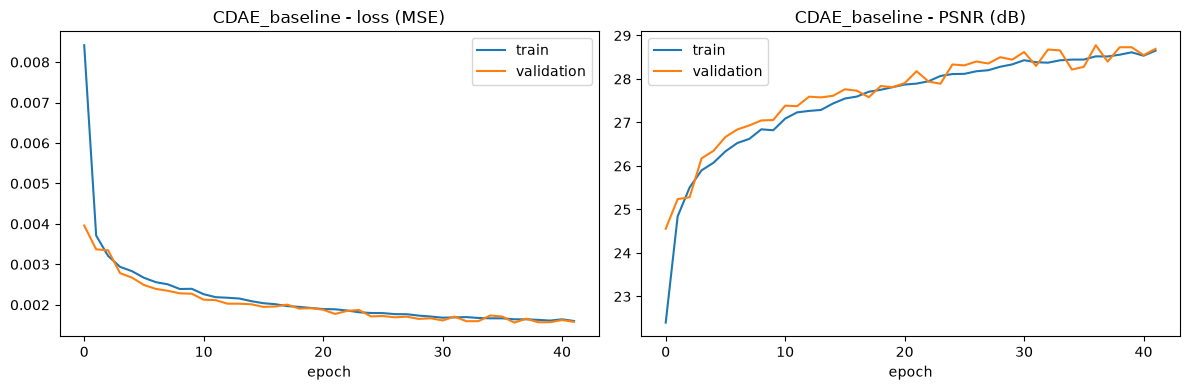

[Block 6.2] OK


In [11]:
print("[Block 6.2] Training curves : starting...")

def plot_history(name):
    h = histories[name].history
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(h["loss"], label="train"); ax1.plot(h["val_loss"], label="validation")
    ax1.set_title(f"{name} - loss (MSE)"); ax1.set_xlabel("epoch"); ax1.legend()
    ax2.plot(h["psnr"], label="train"); ax2.plot(h["val_psnr"], label="validation")
    ax2.set_title(f"{name} - PSNR (dB)"); ax2.set_xlabel("epoch"); ax2.legend()
    plt.tight_layout()
    plt.show()

plot_history("CDAE_baseline")

print("[Block 6.2] OK")

### 6.3 Training the Type 2 model (U-Net)

Same `train()` function as type 1: same data, same noise, same loss, same optimizer, same callbacks.
Only the architecture changes.

In [10]:
print("[Block 6.3] Training UNet : starting...")

train(build_unet())

print("[Block 6.3] OK")

[Block 6.3] Training UNet : starting...
Epoch 1/50


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791715568.769933    6217 shuffle_dataset_op.cc:453] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 4600 of 6952
I0000 00:00:1791715575.422032    6217 shuffle_dataset_op.cc:483] Shuffle buffer filled.
I0000 00:00:1791715575.464497    5937 service.cc:153] XLA service 0x630bd3733750 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791715575.464543    5937 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce GTX 1650 Ti, Compute Capability 7.5 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791715575.648845    5937 dump_mlir_util.cc:269] disabling MLIR 

1738/1738 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.0037 - psnr: 26.1345 - ssim: 0.7531

W0000 00:00:1791715721.355033    5935 assert_op.cc:39] Ignoring Assert operator PSNR/Assert/Assert
W0000 00:00:1791715721.355228    5935 assert_op.cc:39] Ignoring Assert operator PSNR/Assert_1/Assert
W0000 00:00:1791715721.357473    5935 assert_op.cc:39] Ignoring Assert operator SSIM/Assert/Assert
W0000 00:00:1791715721.357740    5935 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_1/Assert
W0000 00:00:1791715721.358114    5935 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_2/Assert
W0000 00:00:1791715721.358331    5935 assert_op.cc:39] Ignoring Assert operator SSIM/Assert_3/Assert


1738/1738 ━━━━━━━━━━━━━━━━━━━━ 177s 79ms/step - loss: 0.0037 - psnr: 26.1345 - ssim: 0.7531 - val_loss: 0.0017 - val_psnr: 28.2393 - val_ssim: 0.8066
Epoch 2/50
1738/1738 ━━━━━━━━━━━━━━━━━━━━ 138s 79ms/step - loss: 0.0015 - psnr: 28.7753 - ssim: 0.8239 - val_loss: 0.0013 - val_psnr: 29.6904 - val_ssim: 0.8391
Epoch 3/50
1738/1738 ━━━━━━━━━━━━━━━━━━━━ 140s 80ms/step - loss: 0.0013 - psnr: 29.6592 - ssim: 0.8475 - val_loss: 0.0017 - val_psnr: 28.4462 - val_ssim: 0.8242
Epoch 4/50
1738/1738 ━━━━━━━━━━━━━━━━━━━━ 140s 81ms/step - loss: 0.0012 - psnr: 29.9440 - ssim: 0.8573 - val_loss: 0.0011 - val_psnr: 30.2971 - val_ssim: 0.8605
Epoch 5/50
1738/1738 ━━━━━━━━━━━━━━━━━━━━ 143s 82ms/step - loss: 0.0012 - psnr: 30.1732 - ssim: 0.8622 - val_loss: 0.0011 - val_psnr: 30.4741 - val_ssim: 0.8605
Epoch 6/50
1738/1738 ━━━━━━━━━━━━━━━━━━━━ 142s 82ms/step - loss: 0.0011 - psnr: 30.6911 - ssim: 0.8689 - val_loss: 0.0013 - val_psnr: 29.7766 - val_ssim: 0.8713
Epoch 7/50
1738/1738 ━━━━━━━━━━━━━━━━━━━━ 140

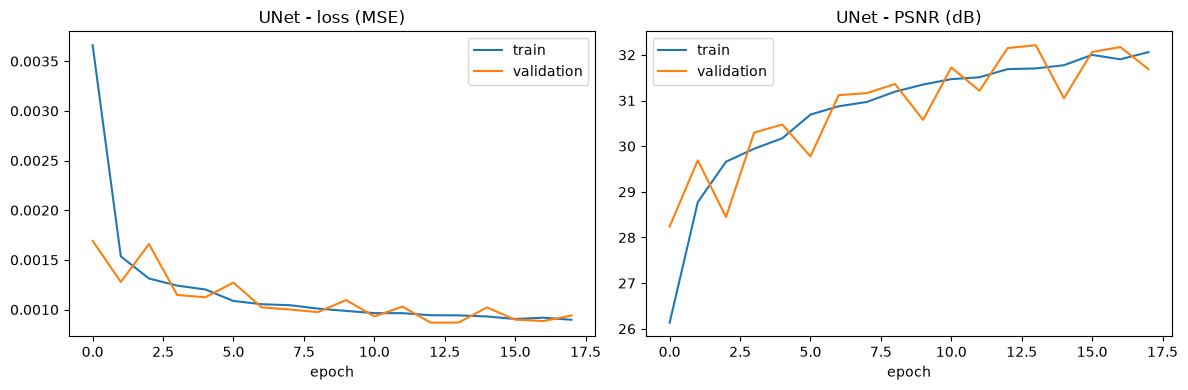

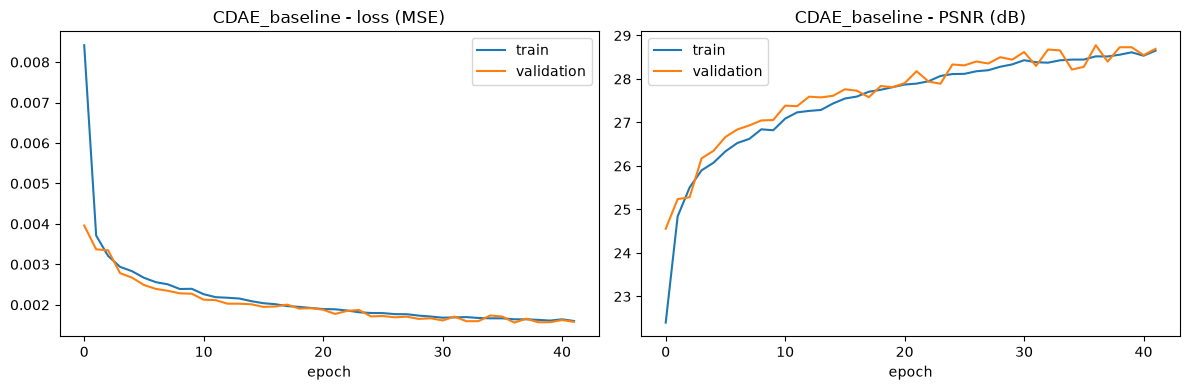

In [12]:
# Reload the two trained models (best epoch of each) instead of training again
models["CDAE_baseline"] = keras.models.load_model("results/denoise_CDAE_baseline.keras")
models["UNet"] = keras.models.load_model("results/denoise_UNet.keras")

# Training curves, read from the CSV logs written during training
def plot_history(name):
    h = pd.read_csv(LOGS / f"denoise_{name}_history.csv")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(h["loss"], label="train"); ax1.plot(h["val_loss"], label="validation")
    ax1.set_title(f"{name} - loss (MSE)"); ax1.set_xlabel("epoch"); ax1.legend()
    ax2.plot(h["psnr"], label="train"); ax2.plot(h["val_psnr"], label="validation")
    ax2.set_title(f"{name} - PSNR (dB)"); ax2.set_xlabel("epoch"); ax2.legend()
    plt.tight_layout()
    plt.show()

for name in models:
    plot_history(name)


### 6.4 Training Curves — Type 2, and comparison with Type 1

Left and middle: loss and PSNR of the U-Net (train / validation), to read in the same way as in 6.2.
Right: the **validation PSNR of every model trained so far**, on the same graph: the higher curve is the
better model, and the gap between the curves is what the architecture brings.

In [11]:
print("[Block 6.4] Training curves : starting...")

plot_history("UNet")

# Validation PSNR of all the trained models, on the same graph
fig, ax = plt.subplots(figsize=(7, 4))
for name, h in histories.items():
    ax.plot(h.history["val_psnr"], label=name)
ax.set_title("Validation PSNR (dB) - all models"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.show()

print("[Block 6.4] OK")

[Block 6.4] Training curves : starting...


NameError: name 'plot_history' is not defined

## 7. Evaluation on the Test Images

PSNR and SSIM on all the **test photos** (after cleaning), never seen during training, **for each type of
noise**, compared with the "do nothing" reference. One column pair per noise type shows which noise a model
removes well and which one it struggles with; the last two columns give the average over the 3 noises.
The table is saved in `results/deliverable2_results.csv` and will get one row per model.

In [15]:
print("[Block 7] Evaluation : starting...")

for name, model in models.items():
    scores[name] = score_all(model)

results = pd.DataFrame(scores).T
results["params"] = [None] + [models[n].count_params() for n in results.index[1:]]
display(results.round(4))
results.to_csv(RESULTS / "deliverable2_results.csv")

print("[Block 7] OK")

[Block 7] Evaluation : starting...


,gaussian PSNR,gaussian SSIM,salt_pepper PSNR,salt_pepper SSIM,poisson PSNR,poisson SSIM,mean PSNR,mean SSIM,params
Noisy input (no denoising),19.2479,0.3357,18.0487,0.4328,19.3027,0.3862,18.8664,0.3849,NaN
UNet,29.7676,0.8403,36.7271,0.9636,30.0094,0.8589,32.1680,0.8876,112547.0
CDAE_baseline,28.2852,0.8097,29.6050,0.8601,28.4236,0.8240,28.7712,0.8313,75651.0


[Block 7] OK


## 8. Case Study

A few **random** test photos (other ones at every run), each one with the **3 types of noise**, side by side: **original** (clean), **noisy**
(what the model receives) and **denoised** by each model, with the PSNR / SSIM of each image compared with
the original.

[Block 8] Case study : starting...
  test photos shown: [1435, 342]


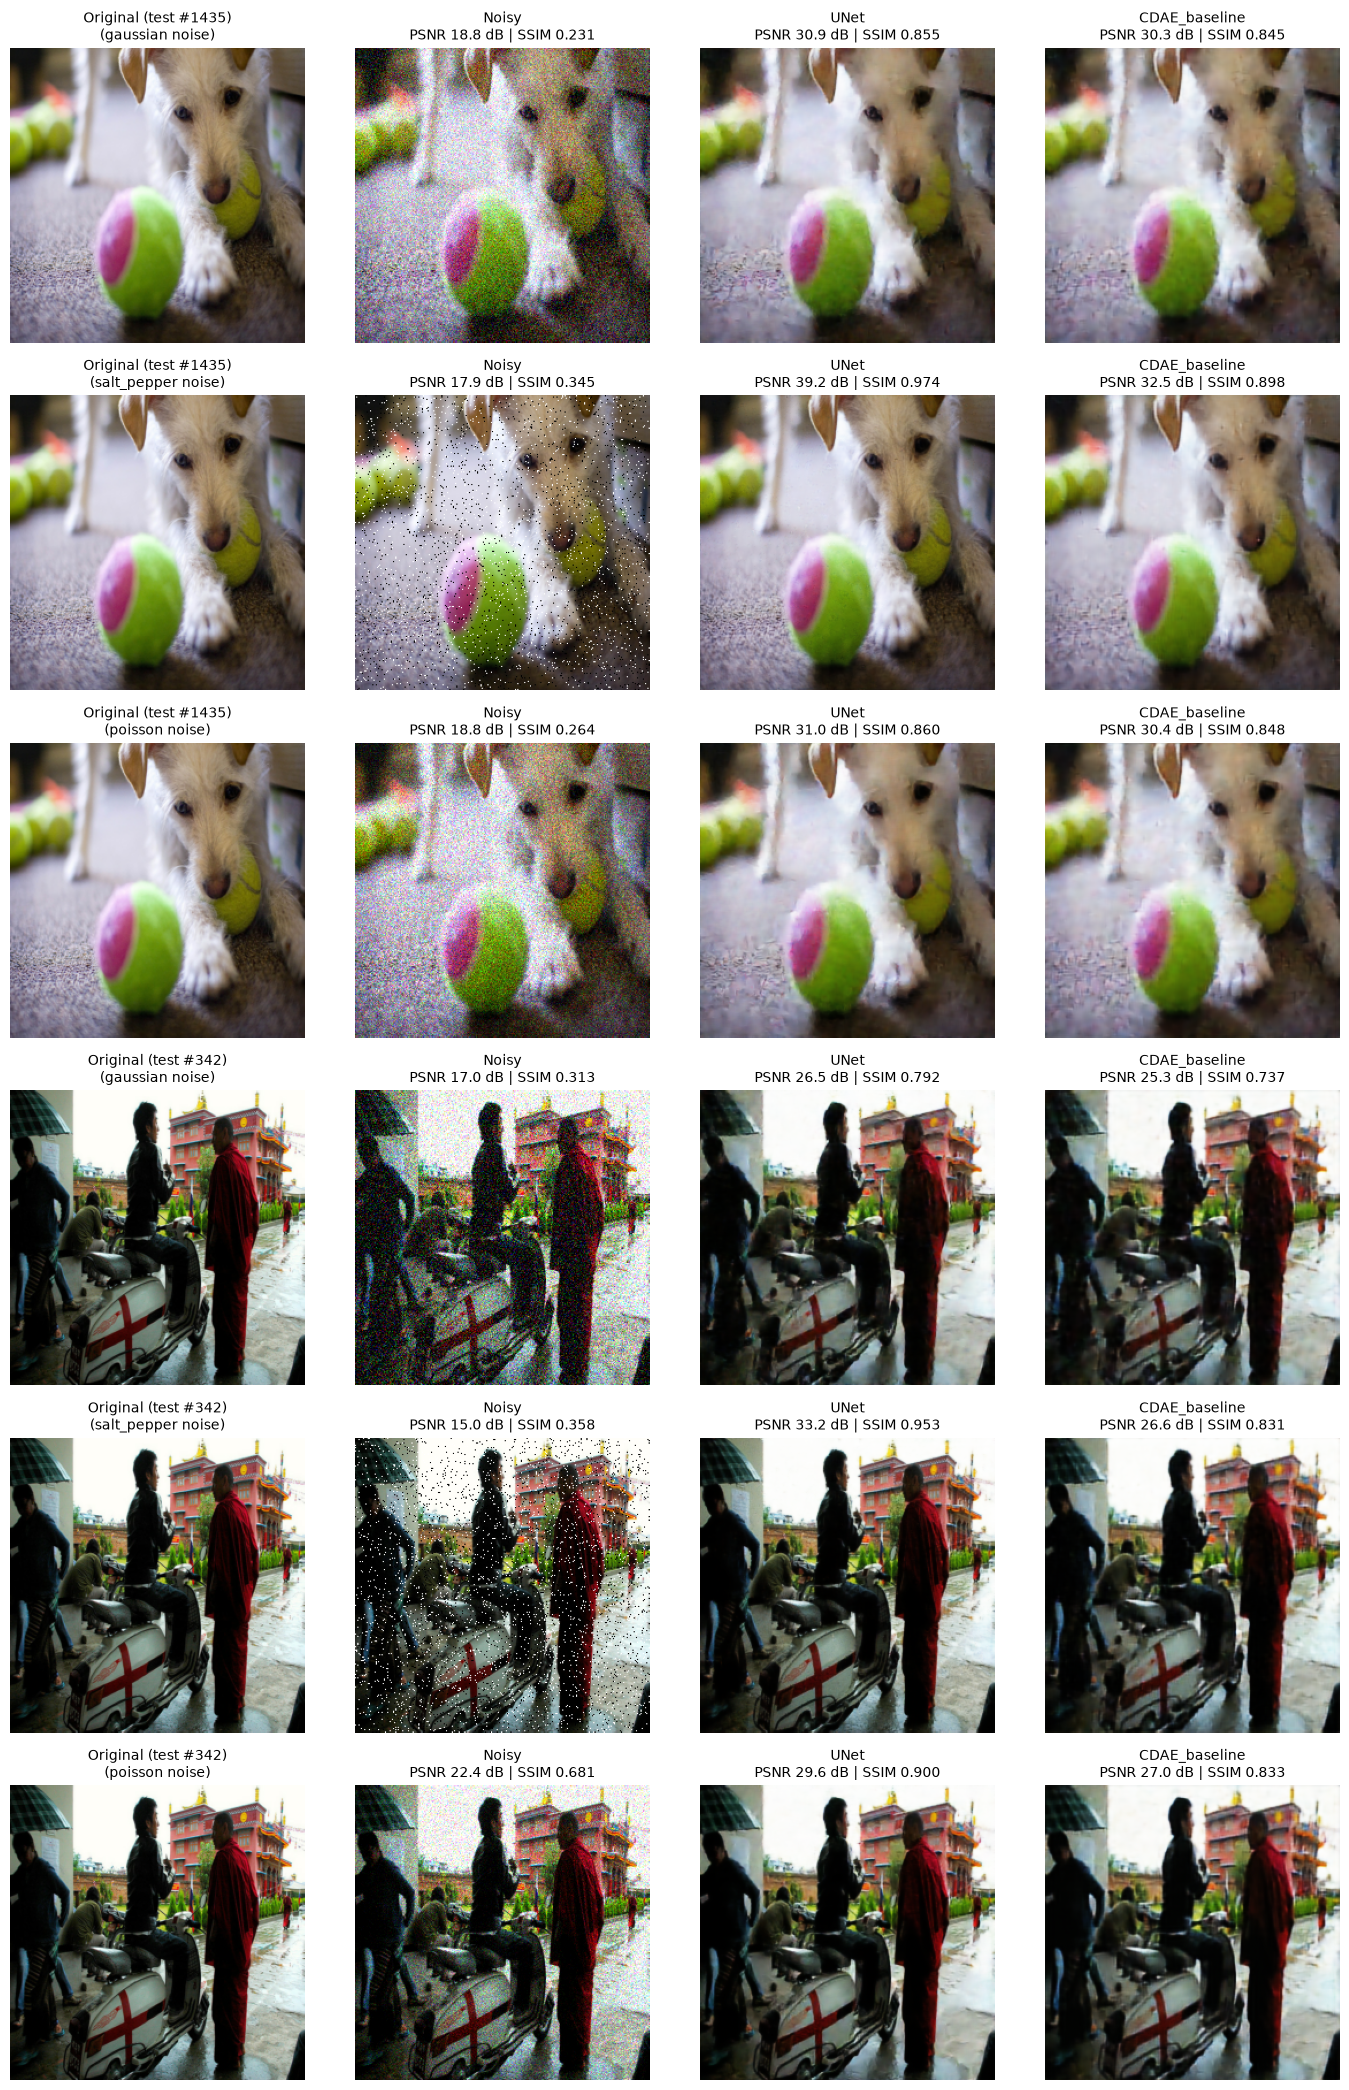

[Block 8] OK


In [16]:
print("[Block 8] Case study : starting...")

# 2 random test photos, other ones at every run (no seed on purpose). Their noise is the one of the test sets
case_images = np.random.default_rng().choice(len(paths["test"]), size=2, replace=False)
print("  test photos shown:", case_images.tolist())
rows = [(kind, i) for i in case_images for kind in NOISE_TYPES]   # each photo with the 3 noises
columns = ["Original", "Noisy"] + list(models)

fig, axes = plt.subplots(len(rows), len(columns), figsize=(3.5 * len(columns), 3.5 * len(rows)), squeeze=False)
for r, (kind, i) in enumerate(rows):
    noisy, clean = test_pair(i, kind)
    x, y = noisy[None], clean[None]   # one photo, as a batch of 1 for the models
    images = {"Original": y, "Noisy": x}
    images.update({name: m(x, training=False) for name, m in models.items()})
    for c, title in enumerate(columns):
        ax = axes[r, c]
        ax.imshow(images[title][0])
        ax.axis("off")
        if title == "Original":
            ax.set_title(f"Original (test #{i})\n({kind} noise)", fontsize=10)
        else:
            p, s = float(psnr(y, images[title])[0]), float(ssim(y, images[title])[0])
            ax.set_title(f"{title}\nPSNR {p:.1f} dB | SSIM {s:.3f}", fontsize=10)
plt.tight_layout()
plt.show()

print("[Block 8] OK")